## Import Library

In [203]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.model_selection import train_test_split 
import seaborn as sns
# Import ColumnTransformer.
from sklearn.compose import ColumnTransformer


## call folder and file stored dataset and  display first 5 records

In [204]:

file = "rwandalandslidedataset/Rwanda_Landslide_Dataset.csv"

df = pd.read_csv(file)

df.head() 

,latitude,longitude,elevation_m,slope_degree,aspect,soil_type,rock_type,rainfall_mm_last_24h,rainfall_mm_last_7d,temperature_c,...,distance_to_river_m,distance_to_road_m,population_density,previous_landslides_count,soil_moisture,earthquake_magnitude_recent,rainfall_anomaly_index,timestamp,region,landslide_occurred
0,-2.384375,30.129272,1512.004340,45.540729,S,Clay,Igneous,1.645904,7.450369,14.902675,...,923.814279,185.785100,668.548348,0.0,0.544169,2.127626,0.901540,2015-12-01 20:00:00,Southern,1
1,-2.422505,29.719482,1342.640530,36.265280,N,Sandy,Igneous,7.293822,57.900464,17.602552,...,254.493320,895.034058,1620.150165,0.0,0.327317,4.420502,-0.000289,2017-02-18 22:00:00,Western,0
2,-2.519032,29.606253,1838.279921,58.647585,W,Peat,Metamorphic,24.019140,203.296509,20.628320,...,1140.521824,736.717148,516.258433,0.0,0.431795,5.074582,-0.754806,2016-10-02 19:00:00,Northern,1
3,-2.352397,30.879907,1756.260990,55.748613,N,Silt,Metamorphic,10.871508,79.644082,20.776244,...,764.908234,292.353973,1098.141045,0.0,0.391022,5.203580,0.206497,2016-02-01 04:00:00,Kigali,1
4,-1.923006,29.603568,1990.654662,25.576538,W,Loam,Metamorphic,24.045195,165.934935,20.098768,...,48.417211,259.867005,622.495718,0.0,0.455890,3.253148,0.470901,2016-09-07 13:00:00,Kigali,1


## Dataset info

In [205]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37322 entries, 0 to 37321
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   latitude                     35342 non-null  float64
 1   longitude                    35369 non-null  float64
 2   elevation_m                  35565 non-null  float64
 3   slope_degree                 35421 non-null  float64
 4   aspect                       35284 non-null  str    
 5   soil_type                    35354 non-null  str    
 6   rock_type                    35612 non-null  str    
 7   rainfall_mm_last_24h         35379 non-null  float64
 8   rainfall_mm_last_7d          35571 non-null  float64
 9   temperature_c                35245 non-null  float64
 10  vegetation_index_ndvi        35474 non-null  float64
 11  land_use                     35611 non-null  str    
 12  distance_to_river_m          35436 non-null  float64
 13  distance_to_road_m         

## summary statistics

In [206]:
df.describe()

,latitude,longitude,elevation_m,slope_degree,rainfall_mm_last_24h,rainfall_mm_last_7d,temperature_c,vegetation_index_ndvi,distance_to_river_m,distance_to_road_m,population_density,previous_landslides_count,soil_moisture,earthquake_magnitude_recent,rainfall_anomaly_index,landslide_occurred
count,35342.000000,35369.000000,35565.000000,35421.000000,35379.000000,35571.000000,35245.000000,35474.000000,35436.000000,35557.000000,35547.000000,35513.000000,35400.000000,35392.000000,35351.000000,37322.000000
mean,-1.959462,29.831149,1640.309834,39.843146,23.184556,156.503136,19.985220,0.455782,1021.114230,488.664885,1007.185918,0.297356,0.388689,3.965722,0.004828,0.500000
std,0.545836,0.613619,299.948280,17.121018,16.884169,131.675162,3.035812,0.230575,1001.749210,488.363530,709.734778,0.547525,0.155770,1.158759,0.984911,0.500007
min,-2.899978,28.800012,900.000000,0.007801,0.117450,0.761930,10.000000,0.100032,0.008493,0.001114,50.000000,0.000000,0.050027,2.000570,-4.207929,0.000000
25%,-2.431144,29.290499,1435.227324,27.779282,11.180946,66.800669,17.911968,0.251056,284.269535,138.896487,497.535780,0.000000,0.269840,2.985161,-0.666346,0.000000
50%,-1.961348,29.834274,1638.244476,45.682074,19.395002,121.246920,20.001604,0.435591,724.945013,338.027071,852.036790,0.000000,0.421614,3.944529,0.010701,0.500000
75%,-1.489744,30.367063,1846.482126,54.011164,30.747611,205.722752,22.016558,0.647852,1424.410991,674.605518,1338.634262,1.000000,0.522603,4.961154,0.672328,1.000000
max,-1.000143,30.899792,2718.350003,59.992506,131.114853,1251.386613,31.889486,0.899928,8000.000000,4763.744922,6271.099238,4.000000,0.599988,5.999936,4.185208,1.000000


## number of missing values

In [207]:
missing_values = df.isna().sum()
display(missing_values[missing_values > 0].sort_values(ascending=False))
print("Total missing values:", int(missing_values.sum()))

temperature_c                  2077
aspect                         2038
timestamp                      1985
latitude                       1980
rainfall_anomaly_index         1971
soil_type                      1968
region                         1957
longitude                      1953
rainfall_mm_last_24h           1943
earthquake_magnitude_recent    1930
soil_moisture                  1922
slope_degree                   1901
distance_to_river_m            1886
vegetation_index_ndvi          1848
previous_landslides_count      1809
population_density             1775
distance_to_road_m             1765
elevation_m                    1757
rainfall_mm_last_7d            1751
land_use                       1711
rock_type                      1710
dtype: int64

Total missing values: 39637


 ## Heatmap of Missing Values

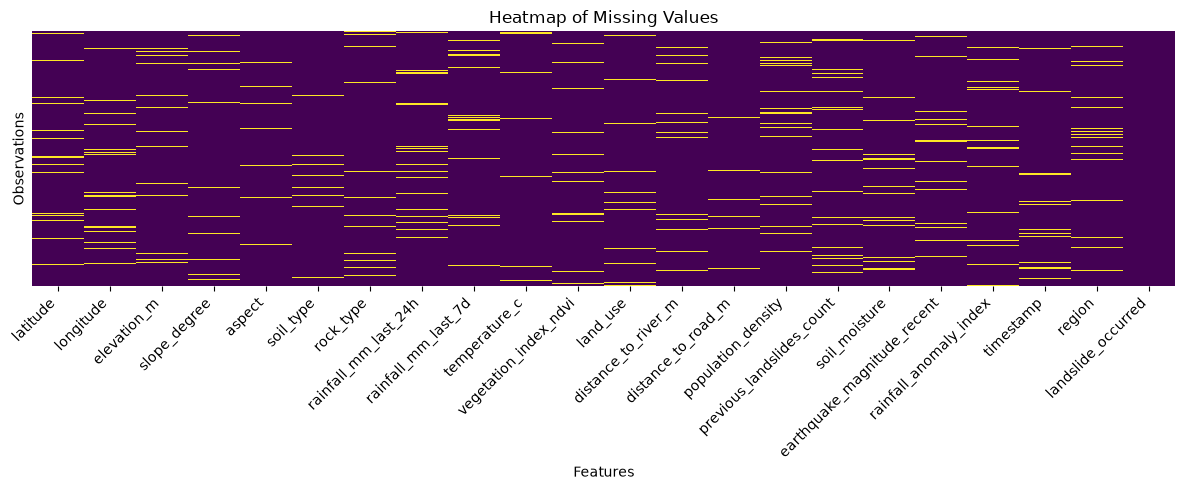

In [208]:

plt.figure(figsize=(12, 5))
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)
plt.title("Heatmap of Missing Values")
plt.xlabel("Features")
plt.ylabel("Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## target distribution

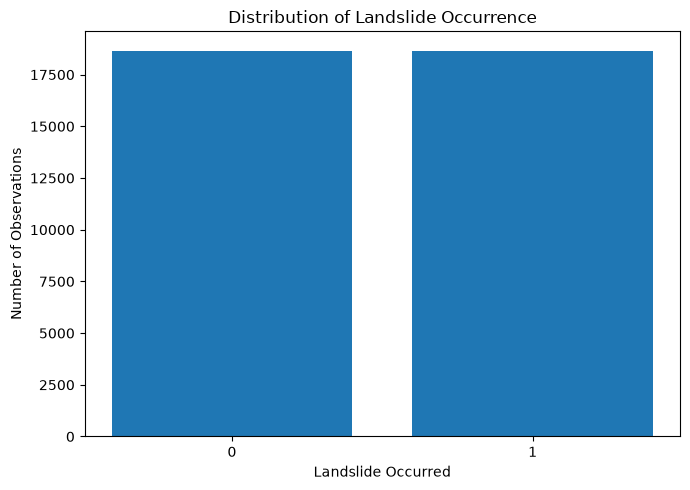

,count
landslide_occurred,
0,18661
1,18661


In [209]:
plt.figure(figsize=(7, 5))
target_counts = df["landslide_occurred"].value_counts().sort_index()
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title("Distribution of Landslide Occurrence")
plt.xlabel("Landslide Occurred")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

display(target_counts.rename("count").to_frame())

### Correlation Heatmap

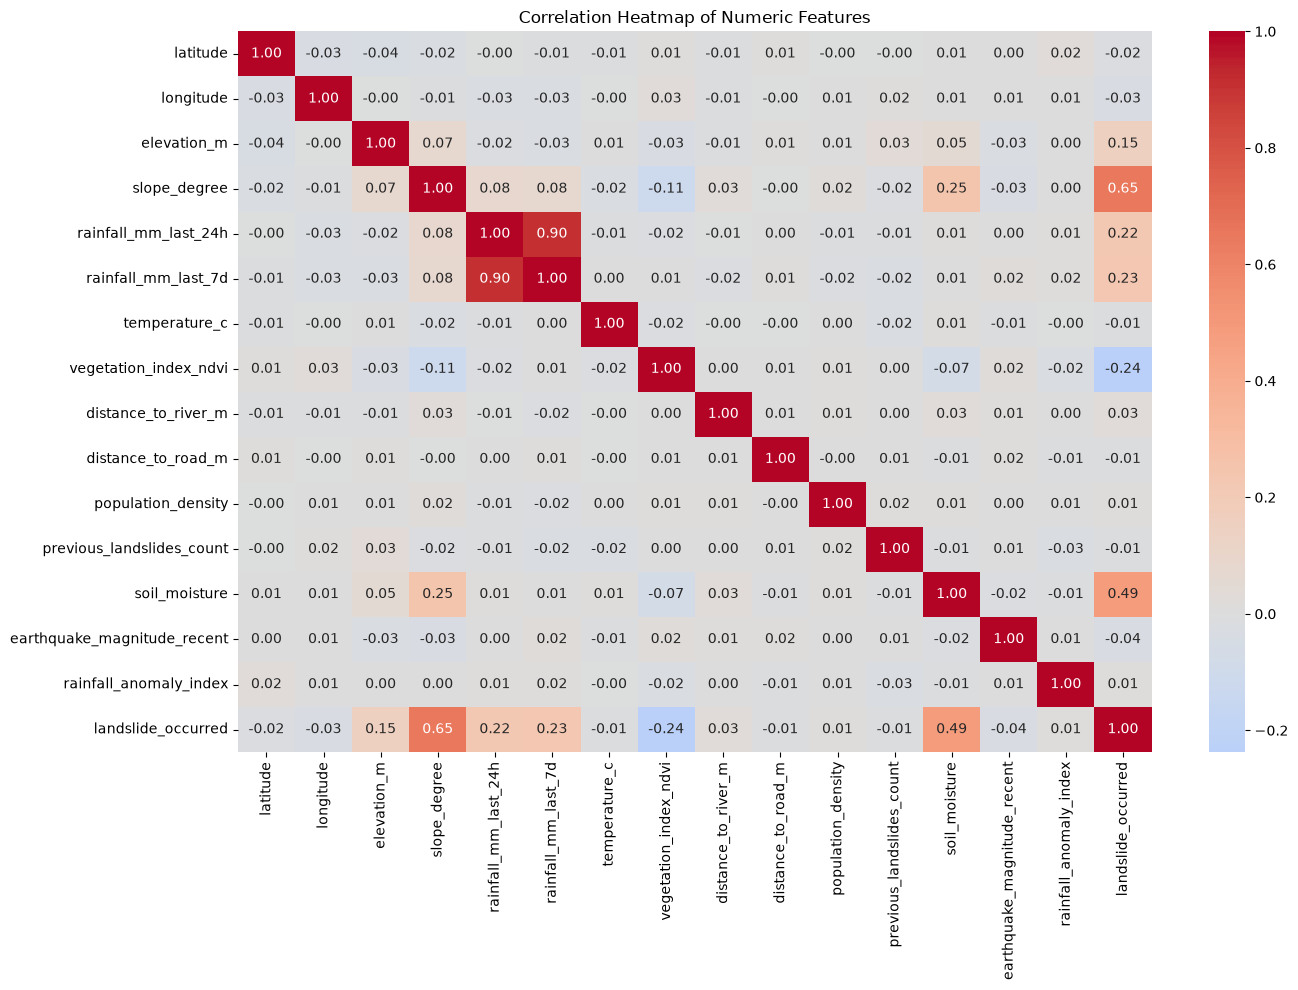

In [210]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

### Handle Missing Values

In [211]:


df_cleaned = df.copy()

num_features = df_cleaned.select_dtypes(include="number").columns.tolist()

num_features.remove("landslide_occurred")
cat_features = df_cleaned.select_dtypes(include="object").columns.tolist()

for column in num_features:
    mean_value = df_cleaned[column].mean()

    df_cleaned[column] = df_cleaned[column].fillna(mean_value)
for column in cat_features:

    mode_value = df_cleaned[column].mode()[0]

    df_cleaned[column] = df_cleaned[column].fillna(mode_value)
missing_values = df_cleaned.isnull().sum()

print("Missing values after imputation:")
display(missing_values)

Missing values after imputation:


C:\Users\uwiho\AppData\Local\Temp\ipykernel_31400\2228041152.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df_cleaned.select_dtypes(include="object").columns.tolist()


latitude                       0
longitude                      0
elevation_m                    0
slope_degree                   0
aspect                         0
soil_type                      0
rock_type                      0
rainfall_mm_last_24h           0
rainfall_mm_last_7d            0
temperature_c                  0
vegetation_index_ndvi          0
land_use                       0
distance_to_river_m            0
distance_to_road_m             0
population_density             0
previous_landslides_count      0
soil_moisture                  0
earthquake_magnitude_recent    0
rainfall_anomaly_index         0
timestamp                      0
region                         0
landslide_occurred             0
dtype: int64


##  Select Numerical Features


In [212]:

num_features = df_cleaned.select_dtypes(include="number").columns.tolist()
num_features.remove("landslide_occurred")
print("Numerical features:")
print(num_features)

Numerical features:
['latitude', 'longitude', 'elevation_m', 'slope_degree', 'rainfall_mm_last_24h', 'rainfall_mm_last_7d', 'temperature_c', 'vegetation_index_ndvi', 'distance_to_river_m', 'distance_to_road_m', 'population_density', 'previous_landslides_count', 'soil_moisture', 'earthquake_magnitude_recent', 'rainfall_anomaly_index']


## Detect Outliers and Total Number of Outliers

In [213]:

outliers = {}
for column in num_features:
    Q1 = df_cleaned[column].quantile(0.25)

    Q3 = df_cleaned[column].quantile(0.75)

    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outliers[column] = (
        (df_cleaned[column] < lower_limit) |
        (df_cleaned[column] > upper_limit)
    ).sum()
outlier_counts = pd.Series(outliers)
display(outlier_counts)
total_outliers = outlier_counts.sum()
print("Total number of outliers:", total_outliers)

latitude                          0
longitude                         0
elevation_m                     146
slope_degree                      0
rainfall_mm_last_24h           1642
rainfall_mm_last_7d            1856
temperature_c                   352
vegetation_index_ndvi             0
distance_to_river_m            1885
distance_to_road_m             2084
population_density             1385
previous_landslides_count      9133
soil_moisture                     0
earthquake_magnitude_recent       0
rainfall_anomaly_index          279
dtype: int64

Total number of outliers: 18762



## Total Number of Outliers

In [214]:

total_outliers = outlier_counts.sum()
print("Total number of outliers:", total_outliers)

Total number of outliers: 18762



## Box Plot of Numerical Features and outlier

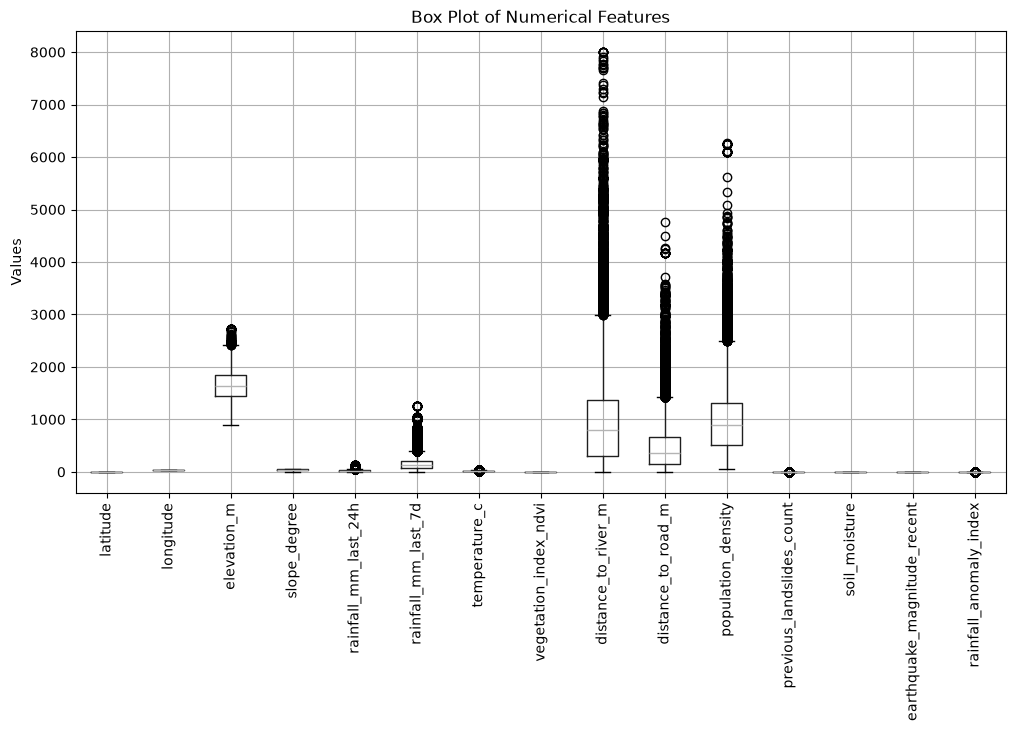

In [215]:

df_cleaned[num_features].boxplot(figsize=(12, 6))

plt.xticks(rotation=90)

plt.title("Box Plot of Numerical Features")

plt.ylabel("Values")

plt.show()


##  Identify Feature Types


In [216]:


num_features = df_cleaned.select_dtypes(include="number").columns.tolist()
num_features.remove("landslide_occurred")
cat_features = df_cleaned.select_dtypes(include="object").columns.tolist()

print("Numerical Features:")
print(num_features)
print("\nCategorical Features:")
print(cat_features)

Numerical Features:
['latitude', 'longitude', 'elevation_m', 'slope_degree', 'rainfall_mm_last_24h', 'rainfall_mm_last_7d', 'temperature_c', 'vegetation_index_ndvi', 'distance_to_river_m', 'distance_to_road_m', 'population_density', 'previous_landslides_count', 'soil_moisture', 'earthquake_magnitude_recent', 'rainfall_anomaly_index']

Categorical Features:
['aspect', 'soil_type', 'rock_type', 'land_use', 'timestamp', 'region']


C:\Users\uwiho\AppData\Local\Temp\ipykernel_31400\622217069.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df_cleaned.select_dtypes(include="object").columns.tolist()


## Create preprocessing for numerical and categorical features

In [217]:

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ), cat_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## Split data into 80% training and 20% testing

In [218]:
X = df_cleaned.drop(columns=["landslide_occurred"])
y = df_cleaned["landslide_occurred"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

print("Testing target distribution:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

X_train shape: (29857, 21)
X_test shape: (7465, 21)
y_train shape: (29857,)
y_test shape: (7465,)

Training target distribution:


,proportion
landslide_occurred,
0,0.499983
1,0.500017


Testing target distribution:


,proportion
landslide_occurred,
0,0.500067
1,0.499933


 ##  the cleaned data has no missing values and that  processed train/test 

In [219]:
print("Cleaned dataset shape:", df_cleaned.shape)
print("Remaining missing values:", int(df_cleaned.isnull().sum().sum()))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training processed columns:", X_train_processed.shape[1])
print("Testing processed columns:", X_test_processed.shape[1])

Cleaned dataset shape: (37322, 22)
Remaining missing values: 0
Training rows: 29857
Testing rows: 7465
Training processed columns: 21
Testing processed columns: 21
